In [ ]:
print("FINAL DATA ANALYTICS PROJECT")
print("Project: Titanic Passenger Survival Analysis")
print("Internship: SWYNEX Technologies")

FINAL DATA ANALYTICS PROJECT
Project: Titanic Passenger Survival Analysis
Internship: SWYNEX Technologies


In [ ]:

import pandas as pd

df = pd.read_csv("titanic dataset.txt")

print("Titanic dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Titanic dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:

print("Dataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          6

In [ ]:

df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

df_clean["Age"] = df_clean["Age"].fillna(
    df_clean["Age"].median()
)

df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

df_clean = df_clean.drop(columns=["Cabin"])

print("Data cleaning completed successfully!")

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

display(df_clean.head())


Data cleaning completed successfully!

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Cleaned dataset shape: (891, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [ ]:

# Overall passenger survival analysis
total_passengers = len(df_clean)
survived = int(df_clean["Survived"].sum())
not_survived = total_passengers - survived

print("Total passengers:", total_passengers)
print("Passengers survived:", survived)
print("Passengers who did not survive:", not_survived)

survival_rate = survived / total_passengers * 100
print("Survival rate:", round(survival_rate, 2), "%")

print("\nSurvival rate by gender:")
print(df_clean.groupby("Sex")["Survived"].mean().mul(100).round(2))

print("\nSurvival rate by passenger class:")
print(df_clean.groupby("Pclass")["Survived"].mean().mul(100).round(2))


Total passengers: 891
Passengers survived: 342
Passengers who did not survive: 549
Survival rate: 38.38 %

Survival rate by gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival rate by passenger class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


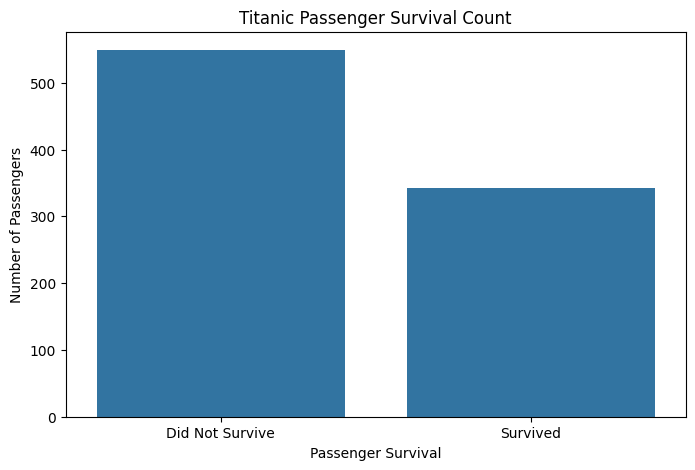

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x="Survived")

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Passenger Survival")
plt.ylabel("Number of Passengers")
plt.xticks([0, 1], ["Did Not Survive", "Survived"])

plt.show()


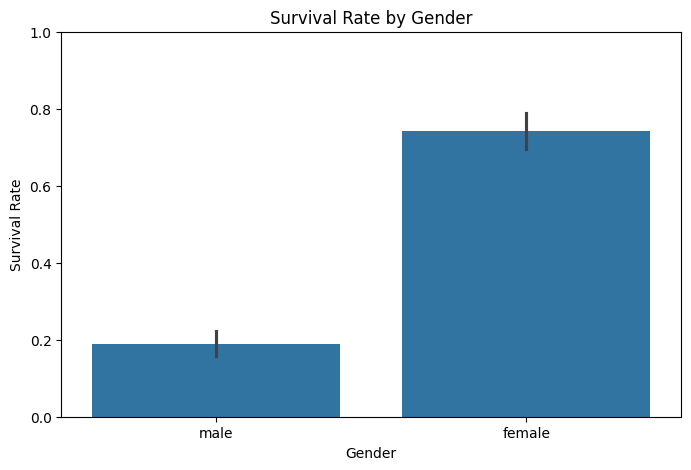

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(data=df_clean, x="Sex", y="Survived")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)

plt.show()


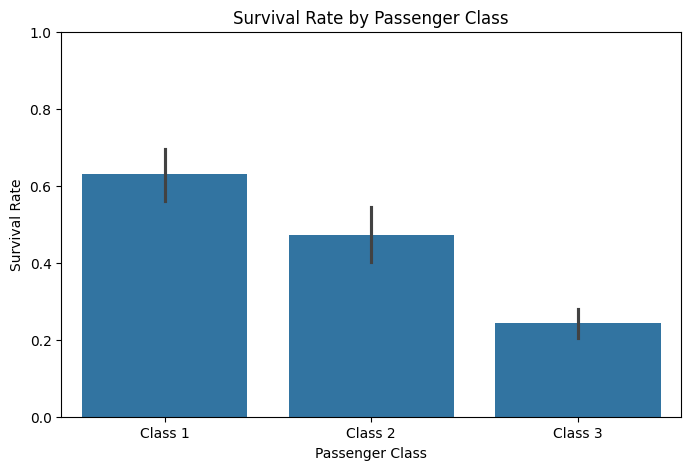

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(data=df_clean, x="Pclass", y="Survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.xticks([0, 1, 2], ["Class 1", "Class 2", "Class 3"])
plt.ylim(0, 1)

plt.show()


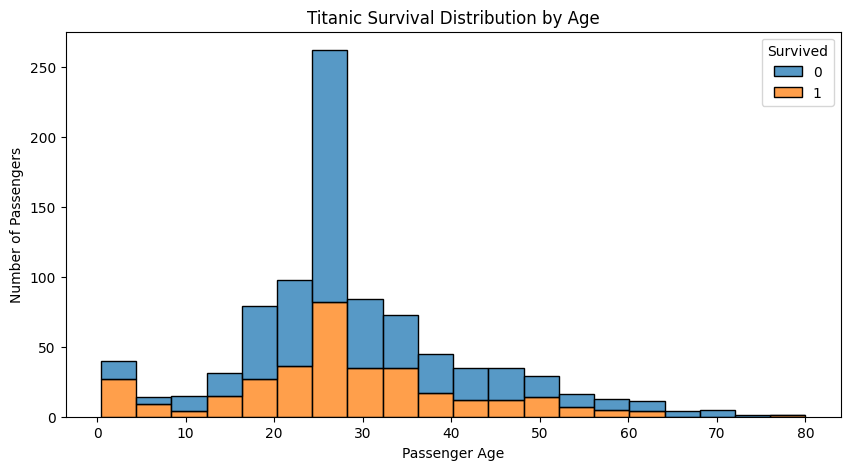

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    hue="Survived",
    bins=20,
    multiple="stack"
)

plt.title("Titanic Survival Distribution by Age")
plt.xlabel("Passenger Age")
plt.ylabel("Number of Passengers")

plt.show()


In [ ]:
from google.colab import userdata
userdata.get('secretName')

# Final Data Analytics Project
## Titanic Passenger Survival AnalysiS
**Internship:** SWYNEX Technologies

### 1. Problem Statement
The objective of this project is to analyze Titanic passenger data and identify factors associated with passenger survival.

### 2. Dataset Information
The dataset contains 891 passenger records and 12 original columns, including age, gender, passenger class, fare, and survival status.

### 3. Data Cleaning
- Checked for missing values and duplicate rows.
- Filled missing Age values using the median.
- Filled missing Embarked values using the mode.
- Removed the Cabin column because it contained many missing values.
- Created a cleaned dataset with 891 rows and 11 columns.

### 4. Tools Used
- Python
- Google Colab
- Pandas
- Matplotlib
- Seaborn
- Power BI for dashboard development

### 5. Key Findings
- Total passengers: 891.
- Passengers who survived: 342.
- Passengers who did not survive: 549.
- Overall survival rate: 38.38%.
- Female survival rate: 74.20%.
- Male survival rate: 18.89%.
- First-class survival rate: 62.96%.
- Second-class survival rate: 47.28%.
- Third-class survival rate: 24.24%.

### 6. Visualizations
Created charts for passenger survival count, survival by gender, survival by passenger class, and survival distribution by age.

### 7. Conclusion
The analysis indicates that passenger survival differed substantially by gender and passenger class. Python was used for data cleaning, analysis, and visualization to communicate the main findings clearly.